# **Squidpy-GPU**

**Accelerated Spatial Analysis**  

**Author:** [Severin Dicks](https://github.com/Intron7)
**Copyright** [scverse](https://scverse.org)

Here, we explore GPU-accelerated spatial analysis using **rapids-singlecell**'s `rsc.gr` module, which mirrors the API of [Squidpy](https://squidpy.readthedocs.io).
We compute spatial autocorrelation metrics — **Moran's I** and **Geary's C** — to detect spatially structured genes within tissue sections.

By running these analyses on GPUs, we achieve faster computation and scalability for large spatial transcriptomics datasets, revealing biological patterns such as **niche-specific expression** and **spatial gradients**.

In [1]:
import cupy as cp
import rapids_singlecell as rsc
import squidpy as sq

In [2]:
import rmm
from rmm.allocators.cupy import rmm_cupy_allocator

rmm.reinitialize(
    managed_memory=False,  # Keep allocations in device memory
    pool_allocator=True,  # default is False
    devices=0,  # GPU device IDs to register. By default registers only GPU 0.
)
cp.cuda.set_allocator(rmm_cupy_allocator)

In [3]:
adata = sq.datasets.visium_hne_adata()

### Constructing a Spatial Graph  

Before computing spatial autocorrelation, we first need to build a **spatial neighbors graph**,  
which defines spatial relationships between cells or tissue spots.  

We compute the graph on the GPU with `rsc.gr.spatial_neighbors_grid`, which mirrors Squidpy's grid graph for Visium spots, from the spatial coordinates stored in `adata.obsm["spatial"]`.

In [4]:
%%time
rsc.gr.spatial_neighbors_grid(adata)

CPU times: user 92.7 ms, sys: 58 ms, total: 151 ms
Wall time: 150 ms


In [5]:
genes = adata.var_names

## Moran's I
To assess spatial structure in gene expression, we compute **spatial autocorrelation**,  
which measures how gene expression levels are spatially distributed across tissue sections.  

In [6]:
%%time
rsc.gr.spatial_autocorr(adata, mode="moran", genes=genes, n_perms=100, use_sparse=False)

CPU times: user 200 ms, sys: 83 ms, total: 283 ms
Wall time: 283 ms


In [7]:
adata.uns["moranI"]

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
Nrgn,0.874753,0.000000,0.000131,0.000000,0.009901,0.000423,0.000000,0.000000,0.016635
Mbp,0.868723,0.000000,0.000131,0.000000,0.009901,0.000371,0.000000,0.000000,0.016635
Camk2n1,0.866545,0.000000,0.000131,0.000000,0.009901,0.000330,0.000000,0.000000,0.016635
Slc17a7,0.861761,0.000000,0.000131,0.000000,0.009901,0.000342,0.000000,0.000000,0.016635
Ttr,0.841988,0.000000,0.000131,0.000000,0.009901,0.000262,0.000000,0.000000,0.016635
...,...,...,...,...,...,...,...,...,...
Slc9a8,-0.026960,0.010027,0.000131,0.000162,0.009901,0.000058,0.017979,0.000311,0.016635
Pramef8,-0.028659,0.006681,0.000131,0.000098,0.009901,0.000060,0.012348,0.000192,0.016635
Klf12,-0.028764,0.006512,0.000131,0.000482,0.009901,0.000069,0.012052,0.000888,0.016635
Gart,-0.028859,0.006361,0.000131,0.000023,0.009901,0.000050,0.011784,0.000047,0.016635


## Geary's C

In addition to **Moran’s I**, we compute **Geary’s C**, another spatial autocorrelation metric.  
While Moran’s I captures **global spatial structure**, **Geary’s C** is more sensitive to **local differences**,  
highlighting regions with abrupt expression changes.  

`use_sparse=True` Enables sparse computation, preventing full matrix densification.
This optimization is handled efficiently in the GPU kernel, significantly reducing memory usage.
Moran’s I also supports use_sparse=True, allowing for efficient computation on large datasets.

In [8]:
%%time
rsc.gr.spatial_autocorr(adata, mode="geary", genes=genes, n_perms=100, use_sparse=True)

CPU times: user 172 ms, sys: 11 ms, total: 183 ms
Wall time: 183 ms


In [9]:
adata.uns["gearyC"]

,C,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
Nrgn,0.126481,0.000000e+00,0.000132,0.000000,0.009901,0.000272,0.000000e+00,0.000000,0.016716
Mbp,0.132855,0.000000e+00,0.000132,0.000000,0.009901,0.000296,0.000000e+00,0.000000,0.016716
Camk2n1,0.135106,0.000000e+00,0.000132,0.000000,0.009901,0.000316,0.000000e+00,0.000000,0.016716
Slc17a7,0.138819,0.000000e+00,0.000132,0.000000,0.009901,0.000321,0.000000e+00,0.000000,0.016716
Ttr,0.156156,0.000000e+00,0.000132,0.000000,0.009901,0.000340,0.000000e+00,0.000000,0.016716
...,...,...,...,...,...,...,...,...,...
AC166344.1,1.079269,2.838968e-12,0.000132,0.402180,0.297030,0.000102,9.736836e-12,0.424834,0.336553
Gm14091,1.083543,1.951603e-13,0.000132,0.396961,0.207921,0.000269,7.015524e-13,0.421711,0.251913
Slc6a5,1.087121,1.869018e-14,0.000132,0.400744,0.396040,0.000025,6.972372e-14,0.424011,0.420387
Soat2,1.093644,2.033682e-16,0.000132,0.409178,0.445545,0.000230,8.090866e-16,0.429167,0.459420


To explore spatial patterns in gene expression, we use **Squidpy’s spatial scatter plot**,  
which overlays expression values onto the spatial coordinates of cells or tissue spots.  

We visualize the expression of **Mbp** (myelin-associated) and **Nrgn** (neuronal marker):  

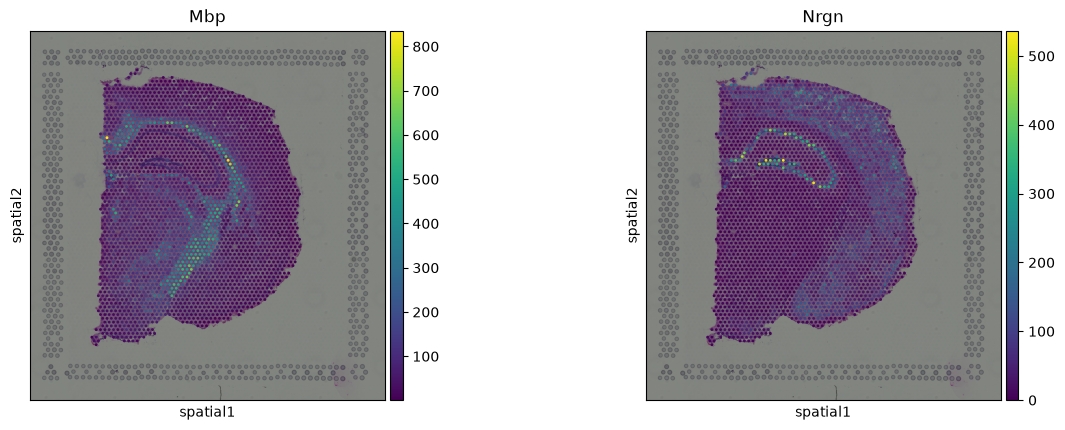

In [10]:
sq.pl.spatial_scatter(adata, color=["Mbp", "Nrgn"])